# Simons Observatory forecast for 8 Flora: scattering (L5) or a flat mm emissivity?

This notebook forecasts how well SO can tell apart two descriptions of Flora's millimetre emission:

* **L5 scattering**: eps_mm(nu) = eps_IR x e_L5(nu), where e_L5(nu) is the effective emissivity from the Meteorites-TeraFlash L5 model (a distortion of the infrared emissivity).
* **Flat effective emissivity**: eps_mm = f x eps_IR with one free, frequency-independent factor f (a different mm emissivity from the IR, with no spectral shape).

**Inputs and assumptions** (change them in the parameter cell):

* Survey length: **4 years** (2025-2028; change `N_YEARS`).
* SO per-day 1-sigma depth: 37 / 25 / 6.9 / 8.3 / 17 / 49 mJy at 30 / 40 / 90 / 150 / 220 / 280 GHz.
* Site: 22d57m31s S, 67d47m15s W. Flora is observed on any day it **transits above 30 degrees** and is **more than 30 degrees from the Sun** (SO's Sun keep-out), to the full depth listed; the **survey duty cycle is 50%** (each observable day counts with weight 0.5, i.e. noise = depth / sqrt(0.5)).
* The thermal baseline is the NEOWISE-style NEATM fit to Flora's WISE photometry (eps_IR = 0.9 in all bands, free albedo in W1/W2), evaluated at Flora's actual geometry on every observable day.
* The IR-model uncertainty is propagated as correlated nuisance parameters (log D, log T1 with the posterior covariance), for two cases: **(A) with the 0.15 mag error floor** used in the paper1 runs, and **(B) statistical errors only** (measured WISE errors, no floor; formally a very poor fit, chi2 = 4938 for 88 points, so (B) is an optimistic limit).
* The statistic is the expected Delta chi^2 between the wrong and the true hypothesis (Asimov data, no noise realisation); significance = sqrt(Delta chi^2).

Not modelled: weather, confusion, beam / bandpass colour corrections, pointing, and shape or rotation effects. The L5 curve at 30 and 40 GHz extrapolates below the fitted TeraFlash band (150-800 GHz) with the Lorenz-Mie model.

In [1]:
import json
import os
import pickle
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")
REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO))
if os.environ.get("ATM_PYLIBS"):  # extra site-packages with astroquery
    sys.path.insert(0, os.environ["ATM_PYLIBS"])

from atm.forecast import (
    ALMA_GHZ,
    SO_DEPTH_MJY,
    SO_GHZ,
    SO_LAT_DEG,
    SO_LON_DEG,
    distinguish,
    distinguishN,
    eCovariance,
    getEphemerides,
    observability,
    posteriorCovariance,
    survey_sigma,
    thermalMjy,
)
from atm.functions.emissivity import ghzListToLambda
from atm.mmfit import fitEmcee, loadWiseFromDb, thermalFluxJy
from atm.models import NEATM
from atm.obs import WISE

plt.rcParams.update({"figure.dpi": 110, "font.size": 9})

## Parameters

In [2]:
OBJECT = {"name": "Flora", "horizons_id": "8", "wise_designation": "8"}
SURVEY_START, N_YEARS = "2025-01-01", 4                       # SO data taking: 4 years
SURVEY_STOP = (pd.Timestamp(SURVEY_START) + pd.DateOffset(years=N_YEARS) - pd.Timedelta(days=1)).strftime("%Y-%m-%d")
MIN_ALTITUDE_DEG = 30.0
DUTY_CYCLE = 0.5
MIN_ELONGATION_DEG = 30.0                                 # SO Sun keep-out: Flora is not observed within 30 deg of the Sun
EPS_IR = 0.9                                              # NEOWISE: fixed emissivity in every WISE band
FLOORS = {"A: 0.15 mag floor": 0.15, "B: statistical errors only": 0.0}
F_CURRENT = 0.65   # eps_mm / eps_IR suggested by the current ACT + ALMA Flora data (implied eps ~0.55-0.6 / 0.9)

WISE_DB = REPO.parent / "atm_data" / "paper1" / "sample.db"
L5_NPZ = REPO / "data" / "emissivity" / "L5_l5c.npz"    # TeraFlash e(f), 20-800 GHz
TABLE_DIR = os.path.join(REPO, "data", "mm_tables", "")   # NEATM lookup tables (trailing slash matters)
CACHE = REPO / "data" / "so_forecast"
CACHE.mkdir(parents=True, exist_ok=True)
print("SO site: lat %.4f deg, lon %.4f deg" % (SO_LAT_DEG, SO_LON_DEG))
pd.DataFrame({"GHz": SO_GHZ, "depth per day [mJy] (1 sigma)": SO_DEPTH_MJY, "with 50% duty [mJy]": SO_DEPTH_MJY / np.sqrt(DUTY_CYCLE)}).round(1)

SO site: lat -22.9586 deg, lon -67.7875 deg


,GHz,depth per day [mJy] (1 sigma),with 50% duty [mJy]
0,30.0,37.0,52.3
1,40.0,25.0,35.4
2,90.0,6.9,9.8
3,150.0,8.3,11.7
4,220.0,17.0,24.0
5,280.0,49.0,69.3


## 1. When can SO observe Flora?

Flora's topocentric declination from JPL Horizons; it transits at altitude 90 - |lat - dec|, and SO observes it on days with transit altitude above 30 degrees.

,days,observable_days,effective_days,r_au,delta_au,median_dec,observable_fraction
year,,,,,,,
2025,365,260,130.0,2.52,2.58,5.14,0.71
2026,365,364,182.0,2.28,1.96,-20.14,1.00
2027,365,206,103.0,1.91,2.65,14.97,0.56
2028,366,258,129.0,2.44,2.86,13.78,0.70


Transit altitude ranges over 44-90 deg, so the 30 deg limit excludes 0 days.
Total: 1088 observable days of 1461; 544 effective full-depth days after the 50% duty cycle.


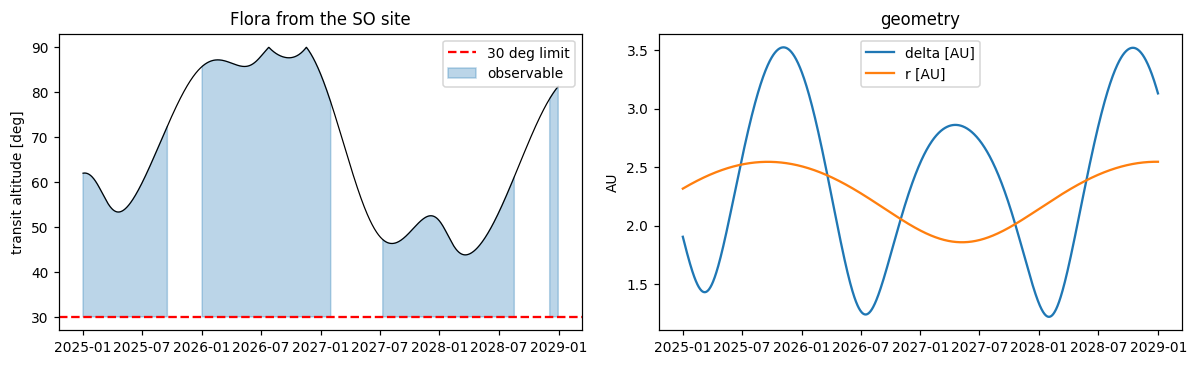

In [3]:
eph = getEphemerides(OBJECT["horizons_id"], SURVEY_START, SURVEY_STOP, cache=CACHE / f"flora_ephemerides_so_{SURVEY_START}_{SURVEY_STOP}.csv")
eph = observability(eph, MIN_ALTITUDE_DEG, DUTY_CYCLE, minElongation=MIN_ELONGATION_DEG)
eph["time"] = pd.to_datetime(eph["date"].str.extract(r"(\d{4}-\w{3}-\d{2})")[0], format="%Y-%b-%d")
eph["year"] = eph["time"].dt.year
yearly = eph.groupby("year").agg(
    days=("observable", "size"),
    observable_days=("observable", "sum"),
    effective_days=("weight", "sum"),
    r_au=("r_au", "median"),
    delta_au=("delta_au", "median"),
    median_dec=("dec_deg", "median"),
)
yearly["observable_fraction"] = yearly["observable_days"] / yearly["days"]
display(yearly.round(2))
print(f"Transit altitude ranges over {eph['transit_alt_deg'].min():.0f}-{eph['transit_alt_deg'].max():.0f} deg, so the {MIN_ALTITUDE_DEG:.0f} deg limit excludes {int((eph['transit_alt_deg'] < MIN_ALTITUDE_DEG).sum())} days.")
print(f"Total: {int(eph['observable'].sum())} observable days of {len(eph)}; {eph['weight'].sum():.0f} effective full-depth days after the {DUTY_CYCLE:.0%} duty cycle.")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].plot(eph["time"], eph["transit_alt_deg"], "k-", lw=0.8)
ax[0].axhline(MIN_ALTITUDE_DEG, c="r", ls="--", label="30 deg limit")
ax[0].fill_between(eph["time"], MIN_ALTITUDE_DEG, eph["transit_alt_deg"], where=eph["observable"], color="C0", alpha=0.3, label="observable")
ax[0].set(ylabel="transit altitude [deg]", title="Flora from the SO site"); ax[0].legend()
ax[1].plot(eph["time"], eph["delta_au"], label="delta [AU]"); ax[1].plot(eph["time"], eph["r_au"], label="r [AU]")
ax[1].set(ylabel="AU", title="geometry"); ax[1].legend()
fig.tight_layout()

## 2. The IR (WISE) model and its uncertainty

NEOWISE-style NEATM fit to Flora's WISE data under the two error treatments. Only (log D, log T1) matter at mm wavelengths; their posterior covariance is the nuisance prior used below.

In [4]:
obs, fitModel = WISE(), NEATM()
NEO = {"eps": EPS_IR, "bands": ["W1", "W2"]}
fits = {}
for name, floor in FLOORS.items():
    cache = CACHE / f"flora_wise_fit_floor{floor:.2f}.pkl"
    if cache.exists():
        s = pickle.loads(cache.read_bytes())
    else:
        data = loadWiseFromDb(WISE_DB, OBJECT["wise_designation"], floor, obs)
        s = fitEmcee(fitModel, obs, data, neowise=NEO, nsteps=4000, burnIn=1500, verbose=False)
        cache.write_bytes(pickle.dumps(s))
    mu, cov = posteriorCovariance(s)
    fits[name] = {"samples": s, "mu": mu, "cov": cov, "chi2": s.attrs["chi2_best"], "N": s.attrs["ndata"]}
    sd = np.sqrt(np.diag(cov))
    print(f"{name:30s} D = {10 ** mu[0] / 1e3:6.1f} km (+/- {100 * np.log(10) * sd[0]:.2f}%)  T1 +/- {100 * np.log(10) * sd[1]:.2f}%  corr = {cov[0, 1] / sd[0] / sd[1]:+.2f}  chi2 = {fits[name]['chi2']:.0f}/{fits[name]['N']}")

Found 138 tables for this model.

Found table file: NEATM_lambda_0000.7500000000e-06_t_100.0000_1200.0000_0.5000_a_0.0000_3.1416_0.0087
Wavelength: 0000.7500000000e-06
Subsolar Temperature:
	Min: 100.0000
	Max: 1200.0000
	Step: 0.5000
Alpha:
	Min: 0.0000
	Max: 3.1416
	Step: 0.0087

Found table file: NEATM_lambda_0000.7682927000e-06_t_100.0000_1200.0000_0.5000_a_0.0000_3.1416_0.0087
Wavelength: 0000.7682927000e-06
Subsolar Temperature:
	Min: 100.0000
	Max: 1200.0000
	Step: 0.5000
Alpha:
	Min: 0.0000
	Max: 3.1416
	Step: 0.0087

Found table file: NEATM_lambda_0000.7870315000e-06_t_100.0000_1200.0000_0.5000_a_0.0000_3.1416_0.0087
Wavelength: 0000.7870315000e-06
Subsolar Temperature:
	Min: 100.0000
	Max: 1200.0000
	Step: 0.5000
Alpha:
	Min: 0.0000
	Max: 3.1416
	Step: 0.0087

Found table file: NEATM_lambda_0000.8062274000e-06_t_100.0000_1200.0000_0.5000_a_0.0000_3.1416_0.0087
Wavelength: 0000.8062274000e-06
Subsolar Temperature:
	Min: 100.0000
	Max: 1200.0000
	Step: 0.5000
Alpha:
	Min: 0.000

## 3. Predicted flux and SO noise on every observable day

The thermal NEATM flux (eps = 1) at the SO frequencies comes from lookup tables, at each day's actual (r, delta, alpha). `Th` below includes eps_IR; the two hypotheses multiply it by e_L5(nu) (L5) or by a constant f (flat). The kernel is d ln Th / d(log D, log T1), used to propagate the IR-fit uncertainty.

In [5]:
import contextlib
import io

with contextlib.redirect_stdout(io.StringIO()):   # the model prints every table it finds
    tabModel = NEATM(tableDir=TABLE_DIR, verbose=False)
    tabModel.loadLambdaTables(ghzListToLambda(SO_GHZ), verbose=False)
day = eph[eph["transit_alt_deg"] >= MIN_ALTITUDE_DEG].reset_index(drop=True)   # keep-out days stay, with zero weight
ok = day["observable"].values                                                  # days SO actually observes
r, dl, al = day["r_au"].values, day["delta_au"].values, np.radians(day["alpha_deg"].values)
sigma = survey_sigma(day["weight"].values)       # (T, B) per-day noise after the duty cycle (inf inside the Sun keep-out)

def thermalTable(logD, logT1):
    return np.column_stack([thermalMjy(tabModel, g, logD, logT1, r, dl, al) for g in SO_GHZ])

pred = {}
for name, f in fits.items():
    logD, logT1 = f["mu"]
    th = EPS_IR * thermalTable(logD, logT1)
    h = 0.01
    dT = (np.log(thermalTable(logD, logT1 + h)) - np.log(thermalTable(logD, logT1 - h))) / (2 * h)
    kernel = np.stack([np.full_like(th, 2 * np.log(10)), dT], axis=-1)
    pred[name] = {"th": th, "kernel": kernel}

e0, covL5 = eCovariance(L5_NPZ, SO_GHZ)
th = pred[next(iter(pred))]["th"]
rows = []
for b, g in enumerate(SO_GHZ):
    snr_day = th[ok, b] * e0[b] / sigma[ok, b]
    rows.append({"GHz": g, "e_L5": e0[b], "median flux, L5 [mJy]": np.median(th[ok, b] * e0[b]), "median per-day sigma [mJy]": np.median(sigma[ok, b]),
                 "median per-day S/N": np.median(snr_day), "survey S/N (observed days)": np.sqrt((snr_day ** 2).sum())})
summary = pd.DataFrame(rows)
display(summary.round(2))

,GHz,e_L5,"median flux, L5 [mJy]",median per-day sigma [mJy],median per-day S/N,survey S/N (observed days)
0,30.0,0.90,1.06,52.33,0.02,0.98
1,40.0,0.86,1.79,35.36,0.05,2.47
2,90.0,0.84,8.85,9.76,0.91,44.24
3,150.0,0.88,25.44,11.74,2.17,105.73
4,220.0,0.90,55.76,24.04,2.32,113.14
5,280.0,0.92,91.10,69.30,1.31,64.13


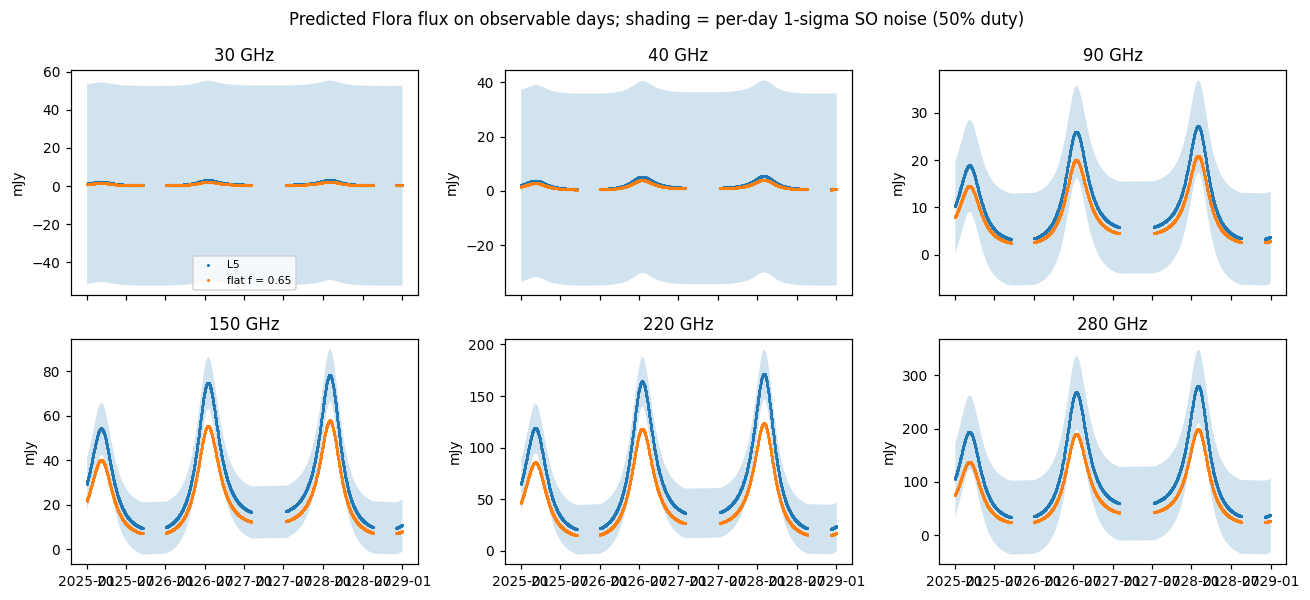

In [6]:
fig, ax = plt.subplots(2, 3, figsize=(12, 5.5), sharex=True)
t_ok = day["time"][ok]
for b, a in enumerate(ax.ravel()):
    a.plot(t_ok, th[ok, b] * e0[b], ".", ms=2, label="L5")
    a.plot(t_ok, th[ok, b] * F_CURRENT, ".", ms=2, label=f"flat f = {F_CURRENT}")
    a.fill_between(t_ok, th[ok, b] * e0[b] - sigma[ok, b], th[ok, b] * e0[b] + sigma[ok, b], color="C0", alpha=0.2, lw=0)
    a.set(title=f"{SO_GHZ[b]:.0f} GHz", ylabel="mJy")
ax[0, 0].legend(fontsize=7)
fig.suptitle("Predicted Flora flux on observable days; shading = per-day 1-sigma SO noise (50% duty)")
fig.tight_layout()

## 4. SED: L5 against flat, with SO precision and the IR-model uncertainty

Spectrum at the median geometry of the survey. Error bars are the full-survey stacked 1-sigma precision per band (daily noise combined with inverse-variance weights after normalising each day's flux to the model). Bands are the IR-model uncertainty on the common normalisation (for the two error treatments).

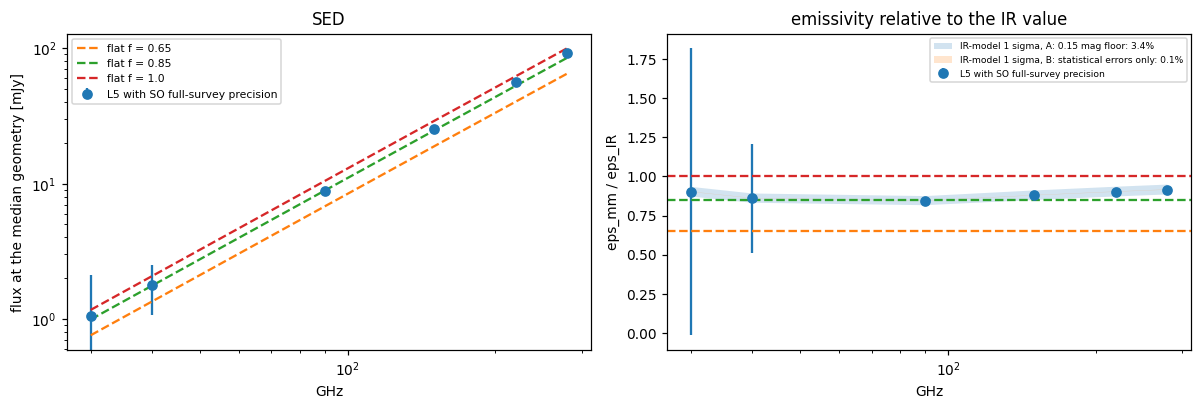

In [7]:
fluxL5 = th * e0[None, :]                                   # (T, B): L5 prediction on each observable day
frac = 1.0 / np.sqrt((fluxL5 ** 2 / sigma ** 2).sum(0))    # stacked fractional precision per band, full survey
mid = np.median(th[ok], axis=0)                              # eps_IR x thermal flux at the median geometry [mJy]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].errorbar(SO_GHZ, mid * e0, mid * e0 * frac, fmt="o", c="C0", label="L5 with SO full-survey precision")
ax[1].errorbar(SO_GHZ, e0, e0 * frac, fmt="o", c="C0", label="L5 with SO full-survey precision")
for f_, c_ in [(F_CURRENT, "C1"), (0.85, "C2"), (1.0, "C3")]:
    ax[0].plot(SO_GHZ, mid * f_, "--", c=c_, label=f"flat f = {f_}")
    ax[1].axhline(f_, ls="--", c=c_)
for name, f in fits.items():   # IR-model uncertainty of the common normalisation (log D and log T1 at 150 GHz)
    k = np.array([2 * np.log(10), np.median(pred[name]["kernel"][ok, 3, 1])])
    norm = float(np.sqrt(k @ f["cov"] @ k))
    ax[1].fill_between(SO_GHZ, e0 * (1 - norm), e0 * (1 + norm), alpha=0.2, label=f"IR-model 1 sigma, {name}: {100 * norm:.1f}%")
ax[0].set(xscale="log", yscale="log", xlabel="GHz", ylabel="flux at the median geometry [mJy]", title="SED")
ax[1].set(xscale="log", xlabel="GHz", ylabel="eps_mm / eps_IR", title="emissivity relative to the IR value")
ax[0].legend(fontsize=7); ax[1].legend(fontsize=6)
fig.tight_layout()

## 5. How well can SO distinguish L5 from a flat emissivity?

Expected Delta chi^2 (Asimov data). Two directions:

1. **Truth = L5**: can SO reject *every* flat emissivity (best-fit f, with the IR-model nuisance parameters free)?
2. **Truth = flat (f)**: can SO reject L5 (fixed e_L5 with its TeraFlash posterior uncertainty, with the IR-model nuisance parameters free)?

Each is shown for the two IR error treatments, and for SO noise alone (IR model held fixed) as a reference.

In [8]:
def run(name, nYears=None, sig=None, **kw):
    sel = np.ones(len(day), bool) if nYears is None else (day["time"] < pd.Timestamp(SURVEY_START) + pd.DateOffset(years=nYears)).values
    s_ = sigma if sig is None else sig
    p = pred[name]
    cov = fits[name]["cov"] if kw.pop("nuisance", True) else np.diag([1e-12, 1e-12])
    return distinguish(p["th"][sel], p["kernel"][sel], s_[sel], cov, e0, **kw)

rows = []
for name in FLOORS:
    for nuis, label in [(False, "SO noise only"), (True, "SO + IR-model uncertainty")]:
        a = run(name, truth="L5", nuisance=nuis)
        b = run(name, truth="flat", fTrue=F_CURRENT, covL5=covL5 if nuis else None, nuisance=nuis)
        rows.append({"IR error treatment": name, "uncertainties": label,
                     "truth L5: reject flat (sigma)": a["significance"], "best-fit flat f": a["f_best"],
                     f"truth flat f={F_CURRENT}: reject L5 (sigma)": b["significance"]})
table = pd.DataFrame(rows)
display(table.round(2))

,IR error treatment,uncertainties,truth L5: reject flat (sigma),best-fit flat f,truth flat f=0.65: reject L5 (sigma)
0,A: 0.15 mag floor,SO noise only,3.59,0.89,47.10
1,A: 0.15 mag floor,SO + IR-model uncertainty,3.59,0.89,8.99
2,B: statistical errors only,SO noise only,3.35,0.89,43.97
3,B: statistical errors only,SO + IR-model uncertainty,3.35,0.89,19.27


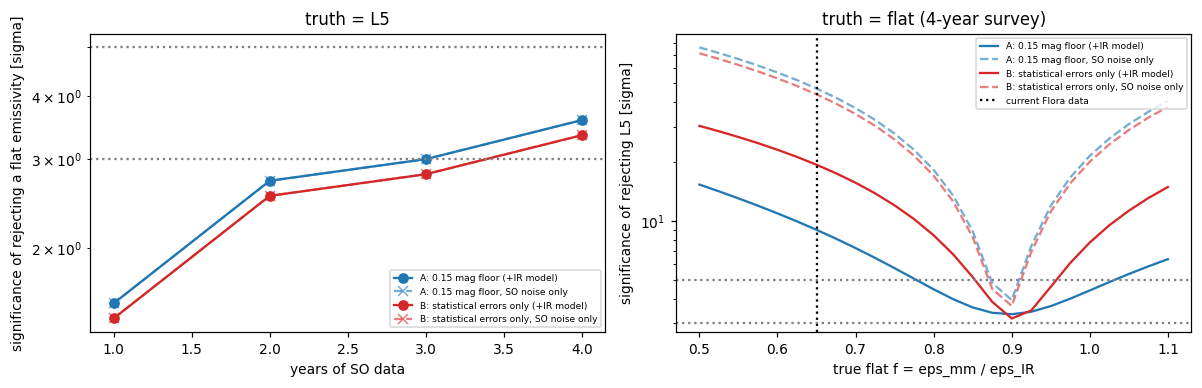

In [9]:
# significance against the survey length, truth = L5, flat alternative
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
years = np.arange(1, N_YEARS + 1)
for name, c_ in zip(FLOORS, ["C0", "C3"]):
    ax[0].plot(years, [run(name, y, truth="L5")["significance"] for y in years], "o-", c=c_, label=f"{name} (+IR model)")
    ax[0].plot(years, [run(name, y, truth="L5", nuisance=False)["significance"] for y in years], "x--", c=c_, alpha=0.6, label=f"{name}, SO noise only")
ax[0].set(xlabel="years of SO data", ylabel="significance of rejecting a flat emissivity [sigma]", yscale="log", title="truth = L5")
ax[0].axhline(3, c="gray", ls=":"); ax[0].axhline(5, c="gray", ls=":"); ax[0].legend(fontsize=6)

# truth = flat(f): rejection of L5 over the full survey
fs = np.linspace(0.5, 1.1, 25)
for name, c_ in zip(FLOORS, ["C0", "C3"]):
    ax[1].plot(fs, [run(name, truth="flat", fTrue=f_, covL5=covL5)["significance"] for f_ in fs], "-", c=c_, label=f"{name} (+IR model)")
    ax[1].plot(fs, [run(name, truth="flat", fTrue=f_, nuisance=False)["significance"] for f_ in fs], "--", c=c_, alpha=0.6, label=f"{name}, SO noise only")
ax[1].axvline(F_CURRENT, c="k", ls=":", label="current Flora data")
ax[1].set(xlabel="true flat f = eps_mm / eps_IR", ylabel="significance of rejecting L5 [sigma]", yscale="log", title=f"truth = flat ({N_YEARS}-year survey)")
ax[1].axhline(3, c="gray", ls=":"); ax[1].axhline(5, c="gray", ls=":"); ax[1].legend(fontsize=6)
fig.tight_layout()

In [10]:
# which bands carry the discrimination? truth = L5: dchi2 contribution per band at the best-fit flat model, full survey
name = list(FLOORS)[0]
a = run(name, truth="L5")
p = pred[name]
model = a["f_best"] * p["th"] * np.exp(p["kernel"] @ a["dtheta"])
w = np.where(np.isfinite(sigma), 1 / np.where(np.isfinite(sigma), sigma, 1) ** 2, 0)
contrib = (w * (e0[None, :] * p["th"] - model) ** 2).sum(0)
resid = ((e0[None, :] * p["th"] - model) / (e0[None, :] * p["th"])).mean(0)
display(pd.DataFrame({"GHz": SO_GHZ, "dchi2 contribution": contrib, "mean fractional difference L5 - best flat": resid}).round(4))

,GHz,dchi2 contribution,mean fractional difference L5 - best flat
0,30.0,0.0001,0.0114
1,40.0,0.0077,-0.0355
2,90.0,5.9389,-0.0551
3,150.0,1.9876,-0.0133
4,220.0,1.9969,0.0125
5,280.0,2.9467,0.0268


### Sensitivity to the Sun keep-out

The 30 degree transit limit never excludes Flora in this window; the observable time is reduced by the 30 degree Sun keep-out (baseline here) and by the 50% duty cycle. The table shows how the result changes with the keep-out angle (0 = no keep-out).

In [11]:
rows = []
for cut in [0, 30, 60, 90]:
    w = DUTY_CYCLE * (day["elong_deg"].values >= cut)
    a = run(list(FLOORS)[0], sig=survey_sigma(w), truth="L5")
    rows.append({"min solar elongation [deg]": cut, "observable days": int((w > 0).sum()), "effective days (x duty)": w.sum(),
                 "truth L5: reject flat (sigma), IR error A": a["significance"]})
display(pd.DataFrame(rows).round(2))

,min solar elongation [deg],observable days,effective days (x duty),"truth L5: reject flat (sigma), IR error A"
0,0,1461,730.5,3.66
1,30,1088,544.0,3.59
2,60,766,383.0,3.50
3,90,525,262.5,3.37


## 6. Adding ALMA

ALMA observes Flora in a single session per band (not daily), and its statistical errors are tiny for a source this bright (the Band 6 observation reached 0.3%), so **calibration**, not noise, sets the precision. The model:

* ALMA Bands 1-9 (centres: B1 43, B2 78, B3 100, B4 144, B5 187, B6 233, B7 343, B8 442, B9 661 GHz; Band 10 lies outside the L5 table; Band 2 is in early science) observed at the geometry of the real 2023-07-31 Flora observation (r = 2.05 AU, delta = 1.12 AU, alpha = 15 deg), where Flora is much brighter than SO sees it.
* Each band has an **independent calibration error** (`ALMA_REL_CAL`, a free assumption: 3% for Bands 2-7, 5% for Band 1, 7% for Bands 8-9) that adds to a 0.5% statistical error; this is what makes the spectral *shape* uncertain.
* Each instrument also has a **common absolute-scale error** (ALMA 5%, SO 2%, `ALMA_ABS_CAL` and `SO_ABS_CAL`) treated as a nuisance parameter; for the flat hypothesis it is absorbed by f, but the cross-calibration between SO and ALMA is constrained jointly.
* The IR-model (log D, log T1) nuisance parameters and the L5 e(nu) posterior covariance (over all the distinct SO and ALMA frequencies) are marginalised as before.

In [12]:
ALMA_REL_CAL = {"B1": 0.05, "B2": 0.03, "B3": 0.03, "B4": 0.03, "B5": 0.03, "B6": 0.03, "B7": 0.03, "B8": 0.07, "B9": 0.07}
ALMA_ABS_CAL, SO_ABS_CAL, ALMA_STAT = 0.05, 0.02, 0.005

alma_obs = json.loads((REPO / "reports" / "flora" / "alma_flora.json").read_text())[0]
geom_alma = (alma_obs["r_au"], alma_obs["delta_au"], alma_obs["alpha_rad"])
bands = list(ALMA_GHZ)
ghz_a = np.array([ALMA_GHZ[b] for b in bands])

def thermal_alma(logD, logT1):
    one = pd.DataFrame({"logD": [logD], "logT1": [logT1]})
    return np.array([1e3 * thermalFluxJy(fitModel, 299792458.0 / (g * 1e9), one, geom_alma, 8)[0] for g in ghz_a])

alma_pred = {}
for name, f in fits.items():
    logD, logT1 = f["mu"]
    th_a = EPS_IR * thermal_alma(logD, logT1)
    h = 0.01
    dT = (np.log(thermal_alma(logD, logT1 + h)) - np.log(thermal_alma(logD, logT1 - h))) / (2 * h)
    alma_pred[name] = {"th": th_a, "kernel": np.stack([np.full_like(th_a, 2 * np.log(10)), dT], axis=-1)}

union = np.unique(np.r_[SO_GHZ, ghz_a])                     # distinct frequencies (for the L5 e covariance)
e0u, covU = eCovariance(L5_NPZ, union)
th_a = alma_pred[list(FLOORS)[0]]["th"]
rel = np.array([ALMA_REL_CAL[b] for b in bands])
display(pd.DataFrame({"band": bands, "GHz": ghz_a, "e_L5": e0u[np.searchsorted(union, ghz_a)], "predicted flux, L5 [mJy]": th_a * e0u[np.searchsorted(union, ghz_a)],
                      "independent error (stat + band calibration)": np.hypot(ALMA_STAT, rel)}).round(3))

,band,GHz,e_L5,"predicted flux, L5 [mJy]",independent error (stat + band calibration)
0,B1,43.0,0.853,7.601,0.05
1,B2,78.0,0.835,24.409,0.03
2,B3,100.0,0.854,40.948,0.03
3,B4,144.0,0.878,86.929,0.03
4,B5,187.0,0.893,148.452,0.03
5,B6,233.0,0.906,232.653,0.03
6,B7,343.0,0.926,510.312,0.03
7,B8,442.0,0.939,850.218,0.07
8,B9,661.0,0.955,1893.520,0.07


In [13]:
def build(name, useSO=True, almaBands=tuple(bands), relScale=1.0):
    """Flattened measurement set (SO daily + ALMA single epoch) for one IR-error scenario."""
    th_l, k_l, s_l, fi_l, so_l, al_l = [], [], [], [], [], []
    if useSO:
        m = ok
        th_l.append(pred[name]["th"][m].ravel()); k_l.append(pred[name]["kernel"][m].reshape(-1, 2)); s_l.append(sigma[m].ravel())
        fi_l.append(np.tile(np.searchsorted(union, SO_GHZ), m.sum()))
        so_l.append(np.ones(th_l[-1].size, bool)); al_l.append(np.zeros(th_l[-1].size, bool))
    sel = [bands.index(b) for b in almaBands]
    if sel:
        t_ = alma_pred[name]["th"][sel]
        th_l.append(t_); k_l.append(alma_pred[name]["kernel"][sel])
        s_l.append(t_ * e0u[np.searchsorted(union, ghz_a[sel])] * np.hypot(ALMA_STAT, relScale * rel[sel]))
        fi_l.append(np.searchsorted(union, ghz_a[sel]))
        so_l.append(np.zeros(len(sel), bool)); al_l.append(np.ones(len(sel), bool))
    th_, k_, s_, fi_ = np.concatenate(th_l), np.concatenate(k_l), np.concatenate(s_l), np.concatenate(fi_l)
    so_m, al_m = np.concatenate(so_l), np.concatenate(al_l)
    groups = [(m_, c_) for m_, c_ in [(so_m, SO_ABS_CAL), (al_m, ALMA_ABS_CAL)] if m_.any()]
    return dict(th=th_, kernel=k_, sigma=s_, priorCov=fits[name]["cov"], e0=e0u[fi_], freqIdx=fi_, covL5=covU, groups=groups)

def sigmaOf(name, truth, fTrue=None, **kw):
    out = distinguishN(**build(name, **kw), truth=truth, fTrue=fTrue)
    return out["significance"]

cases = {
    "SO only (4 yr)": dict(useSO=True, almaBands=()),
    "ALMA B1-B9 only": dict(useSO=False, almaBands=tuple(bands)),
    "ALMA B3+B6+B7 only": dict(useSO=False, almaBands=("B3", "B6", "B7")),
    "ALMA B1+B3+B6 only": dict(useSO=False, almaBands=("B1", "B3", "B6")),
    "ALMA B3-B7 only": dict(useSO=False, almaBands=("B3", "B4", "B5", "B6", "B7")),
    "SO + ALMA B1-B9": dict(useSO=True, almaBands=tuple(bands)),
    "SO + ALMA B3+B6+B7": dict(useSO=True, almaBands=("B3", "B6", "B7")),
}
rows = []
for name in FLOORS:
    for case, kw in cases.items():
        rows.append({"IR error treatment": name, "case": case,
                     "truth L5: reject flat (sigma)": sigmaOf(name, "L5", **kw),
                     f"truth flat f={F_CURRENT}: reject L5 (sigma)": sigmaOf(name, "flat", F_CURRENT, **kw)})
alma_table = pd.DataFrame(rows)
display(alma_table.round(2))

,IR error treatment,case,truth L5: reject flat (sigma),truth flat f=0.65: reject L5 (sigma)
0,A: 0.15 mag floor,SO only (4 yr),3.59,8.03
1,A: 0.15 mag floor,ALMA B1-B9 only,3.21,5.40
2,A: 0.15 mag floor,ALMA B3+B6+B7 only,1.96,5.04
3,A: 0.15 mag floor,ALMA B1+B3+B6 only,1.46,4.53
4,A: 0.15 mag floor,ALMA B3-B7 only,2.02,5.12
5,A: 0.15 mag floor,SO + ALMA B1-B9,4.82,8.59
6,A: 0.15 mag floor,SO + ALMA B3+B6+B7,4.09,8.35
7,B: statistical errors only,SO only (4 yr),3.35,12.78
8,B: statistical errors only,ALMA B1-B9 only,3.21,6.22
9,B: statistical errors only,ALMA B3+B6+B7 only,1.96,5.82


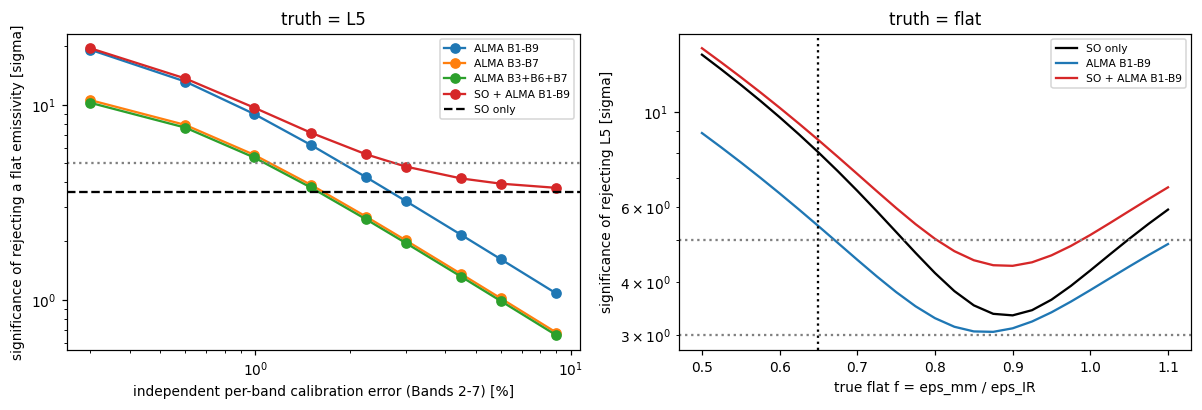

In [14]:
# significance against the independent per-band calibration error (truth = L5, reject flat), IR error treatment A
name = list(FLOORS)[0]
scales = np.array([0.1, 0.2, 0.33, 0.5, 0.75, 1.0, 1.5, 2.0, 3.0])
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for label, kw, c_ in [("ALMA B1-B9", dict(useSO=False, almaBands=tuple(bands)), "C0"), ("ALMA B3-B7", dict(useSO=False, almaBands=("B3", "B4", "B5", "B6", "B7")), "C1"),
                      ("ALMA B3+B6+B7", dict(useSO=False, almaBands=("B3", "B6", "B7")), "C2"), ("SO + ALMA B1-B9", dict(useSO=True, almaBands=tuple(bands)), "C3")]:
    ax[0].plot(100 * scales * 0.03, [sigmaOf(name, "L5", relScale=s_, **kw) for s_ in scales], "o-", c=c_, label=label)
ax[0].axhline(sigmaOf(name, "L5", useSO=True, almaBands=()), c="k", ls="--", label="SO only")
ax[0].axhline(5, c="gray", ls=":")
ax[0].set(xscale="log", yscale="log", xlabel="independent per-band calibration error (Bands 2-7) [%]", ylabel="significance of rejecting a flat emissivity [sigma]", title="truth = L5")
ax[0].legend(fontsize=7)
# truth = flat: significance of rejecting L5 against the true f
fs = np.linspace(0.5, 1.1, 25)
for label, kw, c_ in [("SO only", dict(useSO=True, almaBands=()), "k"), ("ALMA B1-B9", dict(useSO=False, almaBands=tuple(bands)), "C0"), ("SO + ALMA B1-B9", dict(useSO=True, almaBands=tuple(bands)), "C3")]:
    ax[1].plot(fs, [sigmaOf(name, "flat", f_, **kw) for f_ in fs], c=c_, label=label)
ax[1].axvline(F_CURRENT, c="k", ls=":"); ax[1].axhline(5, c="gray", ls=":"); ax[1].axhline(3, c="gray", ls=":")
ax[1].set(yscale="log", xlabel="true flat f = eps_mm / eps_IR", ylabel="significance of rejecting L5 [sigma]", title="truth = flat"); ax[1].legend(fontsize=7)
fig.tight_layout()

In [15]:
# which ALMA bands carry the discrimination? leave one band out of the ALMA-only set (truth = L5)
full = sigmaOf(name, "L5", useSO=False, almaBands=tuple(bands))
rows = [{"dropped band": b, "GHz": ALMA_GHZ[b], "significance without it": sigmaOf(name, "L5", useSO=False, almaBands=tuple(x for x in bands if x != b)),
         "loss [sigma]": full - sigmaOf(name, "L5", useSO=False, almaBands=tuple(x for x in bands if x != b))} for b in bands]
print(f"ALMA B1-B9 alone: {full:.1f} sigma")
display(pd.DataFrame(rows).round(2))

ALMA B1-B9 alone: 3.2 sigma


,dropped band,GHz,significance without it,loss [sigma]
0,B1,43.0,3.14,0.08
1,B2,78.0,2.51,0.70
2,B3,100.0,3.00,0.21
3,B4,144.0,3.21,0.00
4,B5,187.0,3.18,0.03
5,B6,233.0,3.07,0.14
6,B7,343.0,2.72,0.49
7,B8,442.0,3.09,0.12
8,B9,661.0,3.02,0.20


## Summary

In [16]:
from IPython.display import Markdown
lines = []
for _, row in table.iterrows():
    lines.append(f"* **{row['IR error treatment']}**, {row['uncertainties']}: L5 rejects every flat emissivity at **{row['truth L5: reject flat (sigma)']:.1f} sigma** (best-fit flat f = {row['best-fit flat f']:.2f}); "
                 f"a flat f = {F_CURRENT} rejects L5 at **{row[f'truth flat f={F_CURRENT}: reject L5 (sigma)']:.1f} sigma**.")
Markdown("\n".join(lines))

* **A: 0.15 mag floor**, SO noise only: L5 rejects every flat emissivity at **3.6 sigma** (best-fit flat f = 0.89); a flat f = 0.65 rejects L5 at **47.1 sigma**.
* **A: 0.15 mag floor**, SO + IR-model uncertainty: L5 rejects every flat emissivity at **3.6 sigma** (best-fit flat f = 0.89); a flat f = 0.65 rejects L5 at **9.0 sigma**.
* **B: statistical errors only**, SO noise only: L5 rejects every flat emissivity at **3.3 sigma** (best-fit flat f = 0.89); a flat f = 0.65 rejects L5 at **44.0 sigma**.
* **B: statistical errors only**, SO + IR-model uncertainty: L5 rejects every flat emissivity at **3.3 sigma** (best-fit flat f = 0.89); a flat f = 0.65 rejects L5 at **19.3 sigma**.

In [17]:
lines = ["**SO and ALMA together** (IR error treatment A: 0.15 mag floor / B: statistical errors only):"]
for case in cases:
    a = alma_table[(alma_table["case"] == case)]
    ra, rb = a.iloc[0], a.iloc[1]
    c1, c2 = "truth L5: reject flat (sigma)", f"truth flat f={F_CURRENT}: reject L5 (sigma)"
    lines.append(f"* {case}: L5 rejects flat at **{ra[c1]:.1f} / {rb[c1]:.1f} sigma**; a flat f = {F_CURRENT} rejects L5 at {ra[c2]:.1f} / {rb[c2]:.1f} sigma.")
lines.append(f"* With {100 * ALMA_REL_CAL['B3']:.0f}% independent band-to-band calibration, ALMA alone is limited by calibration, not noise: the table above shows how the significance scales with that error (roughly as 1 / calibration error).")
Markdown("\n".join(lines))

**SO and ALMA together** (IR error treatment A: 0.15 mag floor / B: statistical errors only):
* SO only (4 yr): L5 rejects flat at **3.6 / 3.3 sigma**; a flat f = 0.65 rejects L5 at 8.0 / 12.8 sigma.
* ALMA B1-B9 only: L5 rejects flat at **3.2 / 3.2 sigma**; a flat f = 0.65 rejects L5 at 5.4 / 6.2 sigma.
* ALMA B3+B6+B7 only: L5 rejects flat at **2.0 / 2.0 sigma**; a flat f = 0.65 rejects L5 at 5.0 / 5.8 sigma.
* ALMA B1+B3+B6 only: L5 rejects flat at **1.5 / 1.5 sigma**; a flat f = 0.65 rejects L5 at 4.5 / 5.2 sigma.
* ALMA B3-B7 only: L5 rejects flat at **2.0 / 2.0 sigma**; a flat f = 0.65 rejects L5 at 5.1 / 6.0 sigma.
* SO + ALMA B1-B9: L5 rejects flat at **4.8 / 4.6 sigma**; a flat f = 0.65 rejects L5 at 8.6 / 14.1 sigma.
* SO + ALMA B3+B6+B7: L5 rejects flat at **4.1 / 3.9 sigma**; a flat f = 0.65 rejects L5 at 8.4 / 13.7 sigma.
* With 3% independent band-to-band calibration, ALMA alone is limited by calibration, not noise: the table above shows how the significance scales with that error (roughly as 1 / calibration error).

### Caveats

* The L5 e(nu) at 30 and 40 GHz extrapolates the Lorenz-Mie model below the fitted TeraFlash band; the other four SO bands lie inside it.
* The "flat" family has one free parameter, f; real alternatives (a different frequency dependence, subsurface temperature, a different emissivity per band) would be harder or easier to separate from L5.
* Treatment (B) uses a WISE fit that is formally a very poor fit (chi2 = 4938 for 88 points); it is the optimistic limit. The model-shape sensitivity found earlier (dropping W2 or W4 moves the 150 GHz prediction by 30% to 90%) is not included in either case and would dominate if it is real; the normalisation part of it is absorbed by the free f (for the flat hypothesis), but not for L5.
* Daily SO noise is assumed independent between days and bands; Flora's flux is assumed to follow the NEATM model (no rotational variability).